In [1]:
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModel
from datasets import Dataset, ClassLabel
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, 
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score)
import matplotlib.pyplot as plt
from collections import Counter
import random
import os
from tqdm import tqdm

# Seed

Setting seed at 42 for relevant packages to ensure reproducibility.

In [2]:
SEED = 42

def sed_seet(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

sed_seet(SEED)

# Device
Check if using GPU or CPU.


In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Loading Dataset
- Normalising text has filtered away some comments that were either fully
  hashtag or urls to be.
- Drop these rows as they are now NA.

In [ ]:
# loading cleaned CSVs
train_df = pd.read_csv('../data/train_cleaned.csv')
test_df  = pd.read_csv('../data/test_cleaned.csv')

print(f'Train: {train_df.shape}, Test: {test_df.shape}')

Train: (1125667, 9), Test: (283332, 9)


In [5]:
# Check for missing values
print("Missing values in train_df:")
print(train_df.isnull().sum())

Missing values in train_df:
label                        0
comment                      0
comment_clean                0
text_normalized            717
parent_comment               3
parent_text_normalized     376
text_no_punct             1232
subreddit                    0
score                        0
dtype: int64


In [6]:
# drop rows with either text or parent text missing
train_df = train_df.dropna(subset=['text_normalized', 'parent_text_normalized'], how='any')
test_df = test_df.dropna(subset=['text_normalized', 'parent_text_normalized'], how='any')

print(f'Train: {train_df.shape}, Test: {test_df.shape}')

Train: (1124609, 9), Test: (283064, 9)


In [7]:
# filter cols
cols = ['text_normalized', 'parent_text_normalized', 'subreddit', 'label']
train_df = train_df[cols]
test_df = test_df[cols]

In [8]:
# look at distribution of length of text + parent text
total_len = (
    train_df['text_normalized'].str.len()
    + train_df['parent_text_normalized'].str.len()
)
total_len.describe()

count    1.124609e+06
mean     1.881697e+02
std      2.406106e+02
min      2.000000e+00
25%      8.400000e+01
50%      1.320000e+02
75%      2.150000e+02
max      3.906300e+04
dtype: float64

In [9]:
# convert pandas to Dataset
ds_train = Dataset.from_pandas(train_df)
ds_test = Dataset.from_pandas(test_df)

# Feature Engineering

### Tokenization using Distilbert
  - Less parameters than Bert, increasing speed with similar performance level.
  - Tokenize both parent and child comment together to retain context information.
    - **Observation**: Previous iteration using only child comment performed worse.
      - Distilbert's self-attention mechanism allows model to learn the
        relationship between words/tokens.

  - Median length of both child and parent text is 132 while upper quartile
    is 215. So a max token length of 256 is used so that most words are
    accounted for.

  - Dynamic padding will be used during batch processing to be more
    memory and time efficient.

### Subreddit Vocabulary
- Map subreddit to unique IDs.
- There are >16k unique subreddit in the dataset.
  - To reduce dimension and prevent overfitting on subreddits,
    only include those that appeared at least 100 times in the datatest.
  - Those that appear less than 100 times will be treated as unknown
    $\rightarrow$ significantly reduce the vocab size to about 1076.

In [10]:
# hugging face variables
HF_TOKEN = os.environ.get("HF_TOKEN")  # optional, distilbert is a public model
MODEL_NAME = 'distilbert/distilbert-base-uncased'
MAX_LEN = 256

# rust tokenizer for speed.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_TOKEN, use_fast=True)

def tokenize(example):
    '''Tokenize text and parents together, with [SEP] token in between.'''
    return tokenizer(
        example['text_normalized'], 
        example['parent_text_normalized'], 
        truncation=True,
        padding=False,
        max_length=MAX_LEN
    )

In [11]:
# build a vocab of subreddits. Only include those that appear >= 100 times.
sub_counts = Counter(ds_train['subreddit'])
vocab = {"<UNK>": 0}  # reserve 0 for unknown subreddits

for sub, count in sub_counts.items():
    if count >= 100:
        vocab[sub] = len(vocab)

print(f"Number of subreddits: {len(sub_counts)}")
print(f"Vocab size: {len(vocab)}")

Number of subreddits: 16317
Vocab size: 1076


In [12]:
def subreddit_to_id(subreddits: list, vocab: dict) -> list:
    '''Convert list of subreddits to list of ids using a defined vocab'''
    return [vocab.get(sub, 0) for sub in subreddits]

In [13]:
# def log_transform_score(scores: list) -> list:
#     '''
#     Apply log transformation to scores while preserving the sign.
#     Add 1 to the absolute value to avoid log(0).
#     '''
#     scores = np.array(scores)
#     output = np.sign(scores) * np.log1p(np.abs(scores))
#     return output.tolist()

In [14]:
def feature_engineer(ds: Dataset) -> Dataset:
    '''Add engineered features to the dataset'''

    # 1. tokenize comments in batch

    ### tokenize with 2 processes if hardware allows
    cpu = os.cpu_count() 
    num_procs = 2 if (cpu and cpu > 8) else 1
    
    ds = ds.map(tokenize, batched=True, batch_size=1000, num_proc=num_procs)
    
    # 2. map subreddits to ids in batch
    ds = ds.map(lambda x: {'subreddit_id': subreddit_to_id(x['subreddit'], vocab)},
        batched=True,
        batch_size=1000)
    
    return ds

In [16]:
ds_train_fe = feature_engineer(ds_train)

Map (num_proc=2):   0%|          | 0/1124609 [00:00<?, ? examples/s]

Map:   0%|          | 0/1124609 [00:00<?, ? examples/s]

# Classifier

### Architecture:
  - Disilbert Transformer Model
  - Embedding Layer for Subreddit
  - Classifier Layer

Given that the DistilBERT has approximately 66 million parameters, to
reduce training speed, only the last 3 layers of the model was unfreezed
to fine-tuned during gradient descent.

This approach will still allow semantic relationship to be learnt from the
reddit dataset.

The Classifier is a Multi-Layer Percepron (MLP) that fuses both cls
embedding of the BERT layer and the Subreddit embedding layer.

2 hidden layers were used to improve reasoning. Each layer has:

- `BatchNorm1D` was used to normalised the the vectors to a Normal Distribution.
- `ReLU` is used to introduce non-linearity to the model.
- `Dropout` acts as regularisation to prevent overfitting by randomly dropping data,
  preventing the network on relying specific nodes.

In [17]:
class SarcasmPredictor(nn.Module):
    def __init__(self,
        tokenizer_dim: int,
        subreddit_vocab_size: int,
        subreddit_dim: int,
        dropout: float = 0.2):
        
        super().__init__()

        # initialise model
        self.tokenizer = AutoModel.from_pretrained(MODEL_NAME, token=HF_TOKEN)
        
        # freeze BERT parameters to prevent training on them
        for param in self.tokenizer.parameters():
            param.requires_grad = False

         # unfreeze the last 3 layer of tokenizer for fine-tuning
        for param in self.tokenizer.transformer.layer[-3:].parameters():
            param.requires_grad = True

        # create embedding layer for subreddit
        self.subreddit_layer = (
            nn.Embedding(subreddit_vocab_size, subreddit_dim, padding_idx=0)
        )
        
        # concatenated input dimension of tokenizer and subreddit embedding
        self.input_dim = tokenizer_dim + subreddit_dim

        # classifier layer
        self.classifier = nn.Sequential(
            # first layer
            nn.Linear(self.input_dim, 512),  # reduce dimensionality
            nn.BatchNorm1d(512),  # normalise vectors
            nn.ReLU(),  # add non-linearity
            nn.Dropout(dropout),  # add dropout for regularisation
            # second layer
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),
            # output layer
            nn.Linear(128, 1)
        )
    

    def forward(self,
        text_inputs: dict[str, torch.Tensor],
        subreddit_ids: torch.Tensor):

        # get tokenizer embeddings
        outputs = self.tokenizer(**text_inputs)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # get [CLS] token

        # get subreddit embeddings
        subreddit_embeds = self.subreddit_layer(subreddit_ids)

        # concatenate all features
        combined = torch.cat([cls_embedding, subreddit_embeds], dim=1)

        # pass through classifier
        logits = self.classifier(combined)
        return logits

# Train-Val Split

In [18]:
# cast to torch
ds_train_fe.set_format(type='torch', columns=['input_ids', 'attention_mask', 'subreddit_id', 'label'])

# convert label column to ClassLabel for stratified splitting
features = ds_train_fe.features
features['label'] = ClassLabel(num_classes=2, names=['not_sarcastic', 'sarcastic'])
ds_train_fe = ds_train_fe.cast(features)

# split to train and validation sets
ds_train_dict = ds_train_fe.train_test_split(test_size=0.1, seed=SEED, stratify_by_column='label')
ds_train = ds_train_dict['train']
ds_val = ds_train_dict['test']

Casting the dataset:   0%|          | 0/1124609 [00:00<?, ? examples/s]

# Loader

In [19]:
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 8
pin_memory = True if DEVICE.type == 'cuda' else False
num_workers = (os.cpu_count() or 0) // 2

In [20]:
def dynamic_collate_fn(batch):
    '''
    Custom collate function to handle dynamic padding
    and subreddit id in batches.

    Tokenizer should be defined above in global scope.
    '''
    # pad text features
    input_ids = [item['input_ids'] for item in batch]
    attention_mask = [item['attention_mask'] for item in batch]

    padded_text = tokenizer.pad(
        {'input_ids': input_ids, 'attention_mask': attention_mask},
        padding='longest',
        return_tensors='pt'
    )

    subreddit_ids = torch.stack([item['subreddit_id'] for item in batch])
    labels = torch.stack([item['label'] for item in batch])

    return {
        'input_ids': padded_text['input_ids'],
        'attention_mask': padded_text['attention_mask'],
        'subreddit_id': subreddit_ids,
        'label': labels
    }

In [21]:
train_loader = DataLoader(ds_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    persistent_workers=num_workers > 0,
    collate_fn=dynamic_collate_fn
)

val_loader = DataLoader(ds_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    persistent_workers=num_workers > 0,
    collate_fn=dynamic_collate_fn
)

# Training

### Loss Function
  - **BCEWithLogitsLoss**
    - Suitable for Binary Classification
    - Combines Sigmoid and Binary Cross Entropy

### Optimiser
- **AdamW**
  - Uses Adpative Learning Rate and Momentum for faster convergence while still being stable.
  - Applies weight decay directly to weights, improving regularization.


### Learning Rate Scheduler
- Used to dynamically adjust learning rate during training.
- **Cosine Annealing** is used.

### Scaler
- GPU Optimization:  Automatic Mixed Precision


### Validation Set Evaluation
- During training, validation set is used for evaluation.
- This is to detect overfitting and ensure model is generalising well.
- Metrics tracked:
  - **BCEWithLogitsLoss**
  - Accuracy
  - Precision
  - Recall
  - F1 Score

### Early Stopping

A custom Class for early stopping.
  - If validation loss stops decreasing significantly, early stopping is triggered.

In [22]:
def train(model, loader, criterion, optimiser, scheduler, scaler, device):
    model.train()
    total_loss = 0

    for batch in loader:
        # move batch to device
        batch = {k: v.to(device) for k, v in batch.items()}

        optimiser.zero_grad()
        # use fp16 for faster training on GPU if supported
        with torch.autocast(device_type=device.type):
            # forward pass
            logits = model(
                text_inputs={
                    'input_ids': batch['input_ids'],
                    'attention_mask': batch['attention_mask'],
                },
                subreddit_ids=batch['subreddit_id']
            )

            # compute loss
            labels = batch['label'].float()
            loss = criterion(logits.squeeze(), labels)
            total_loss += loss.item()

        # backward pass and optimization
        if scaler:
            scaler.scale(loss).backward()
            scaler.unscale_(optimiser)  # unscale gradients for clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
            scaler.step(optimiser)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()

        # scheduler step after each batch for finer control over learning rate
        scheduler.step()

    avg_loss = total_loss / len(loader)
    return avg_loss

In [23]:
def evaluate_val(model, loader, criterion, device):
    model.eval()
    all_preds = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():  # disable gradient calculation
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            logits = model(
                text_inputs={
                    'input_ids': batch['input_ids'],
                    'attention_mask': batch['attention_mask'],
                },
                subreddit_ids=batch['subreddit_id']
            )

            # compute loss for monitoring
            labels = batch['label'].float()
            loss = criterion(logits.squeeze(), labels)
            total_loss += loss.item()

            # get probabilities from logits using sigmoid
            preds = torch.sigmoid(logits).squeeze()  # shape: (batch_size)
            # threshold at 0.5 for binary classification
            preds = (preds > 0.5).int().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(batch['label'].cpu().numpy())
    
    # compute metrics
    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary')
    return avg_loss, accuracy, precision, recall, f1

In [ ]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_val_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_val_loss is None:
            self.best_val_loss = val_loss
        elif val_loss > self.best_val_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_val_loss = val_loss
            self.counter = 0

    def save_checkpoint(self, model, path):
        '''
        Save the model checkpoint to the specified path.
        '''
        torch.save(model.state_dict(), path)

In [ ]:
# model params
BERT_DIM = 768  # DistilBERT dimension based on documentation
SUBREDDIT_SIZE = len(vocab)
SUBREDDIT_DIM = min(50, SUBREDDIT_SIZE // 2)  # avoid overfitting. A method by FastAI.
DROPOUT = 0.2

In [ ]:
NUM_EPOCH = 30
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 8

# checkpoint path
os.makedirs('checkpoints', exist_ok=True)
checkpoint_path = 'checkpoints/sarcasm_predictor_final.pth'

# range of learning rates to test
learning_rates = [1e-5, 2e-5, 5e-5]

# store all loss histories
all_results = {}

# store best overall result
best_overall_val_loss = float('inf')
best_lr = None


for lr in learning_rates:
    print(f"\n{"="*20} Validating with LR: {lr} {"="*20}")

    # initialise model
    model = SarcasmPredictor(
        tokenizer_dim=BERT_DIM,
        subreddit_vocab_size=SUBREDDIT_SIZE,
        subreddit_dim=SUBREDDIT_DIM,
        dropout=DROPOUT
    )
    model.to(DEVICE)

    # initialise early stopper
    early_stopper = EarlyStopping(patience=3, min_delta=0.001)

    # initialise loss function, optimiser, scheduler and scalar
    loss_func = nn.BCEWithLogitsLoss()
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=NUM_EPOCH*BATCH_SIZE)
    scaler = torch.amp.GradScaler() if DEVICE.type == 'cuda' else None

    # loss for current learning rate
    train_losses = []
    val_losses = []


    for epoch in tqdm(range(NUM_EPOCH), desc="Training"):
        train_loss = train(model, train_loader, loss_func, optimiser, scheduler, scaler, DEVICE)
        train_losses.append(train_loss)

        # evaluate on validation set
        val_loss, val_acc, val_prec, val_rec, val_f1 = evaluate_val(model, val_loader, loss_func, DEVICE)
        val_losses.append(val_loss)
        
        output = (
            f"Epoch {epoch+1}/{NUM_EPOCH} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val Prec: {val_prec:.4f} | "
            f"Val Rec: {val_rec:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )
        print(output)

        # check if this is the best performing model across ALL learning rates
        if val_loss < best_overall_val_loss:
            best_overall_val_loss = val_loss
            # Save the best weights found so far
            best_lr = lr
            torch.save(model.state_dict(), checkpoint_path)
            print(f"--> New best overall model found with LR {lr}")

        # check for early stopping
        early_stopper(val_loss)
        if early_stopper.early_stop:
            print("Early stopping triggered.")
            break

    # store losses for lr
    all_results[lr] = {
        "train_losses": train_losses,
        "val_losses": val_losses
    }

In [ ]:
# plot train loss vs validation loss
train_losses = all_results.get(best_lr, {}).get("train_losses", [])
val_losses = all_results.get(best_lr, {}).get("val_losses", [])


plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss vs Validation Loss')
plt.legend(loc='upper right')
plt.show()

# Evaluation on Test Set

In [25]:
BATCH_SIZE = 32 if DEVICE.type == 'cuda' else 8

ds_test_fe = feature_engineer(ds_test)
ds_test_fe.set_format(type='torch', columns=['input_ids', 'attention_mask', 'subreddit_id', 'label'])
test_loader = DataLoader(ds_test_fe,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=pin_memory,
    num_workers=num_workers,
    persistent_workers=num_workers > 0,
    collate_fn=dynamic_collate_fn
)

test_loader

Map (num_proc=2):   0%|          | 0/283064 [00:00<?, ? examples/s]

Map:   0%|          | 0/283064 [00:00<?, ? examples/s]

In [26]:
def evaluate_test(model, loader, device, loss_func):
    all_labels = []
    all_preds = []
    all_prob_preds = []

    model.eval()
    with torch.no_grad():  # disable gradient calculation
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            logits = model(
                text_inputs={
                    'input_ids': batch['input_ids'],
                    'attention_mask': batch['attention_mask'],
                },
                subreddit_ids=batch['subreddit_id'],
            )

            # compute loss for monitoring
            labels = batch['label'].float()
            loss = loss_func(logits.squeeze(), labels)

            # get probabilities from logits using sigmoid
            probs = torch.sigmoid(logits).squeeze()  # shape: (batch_size)
            all_prob_preds.extend(probs.cpu().numpy())

            # threshold at 0.5 for binary classification
            preds = (probs > 0.5).int().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(batch['label'].cpu().numpy())
    
    # return true labels, predicted labels and predicted probabilities
    return all_labels, all_preds, all_prob_preds

In [ ]:
# load model with saved parameters
model = SarcasmPredictor(
    tokenizer_dim=BERT_DIM,
    subreddit_vocab_size=SUBREDDIT_SIZE,
    subreddit_dim=SUBREDDIT_DIM,
    dropout=DROPOUT
)

checkpoint_path = 'checkpoints/sarcasm_predictor_final.pth'

model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
model.to(DEVICE)

loss_func = nn.BCEWithLogitsLoss()

y_true, y_pred, y_prob = evaluate_test(model, test_loader, DEVICE, loss_func)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


               precision    recall  f1-score   support

not_sarcastic     0.7595    0.8118    0.7848    141504
    sarcastic     0.7979    0.7430    0.7695    141560

     accuracy                         0.7774    283064
    macro avg     0.7787    0.7774    0.7771    283064
 weighted avg     0.7787    0.7774    0.7771    283064



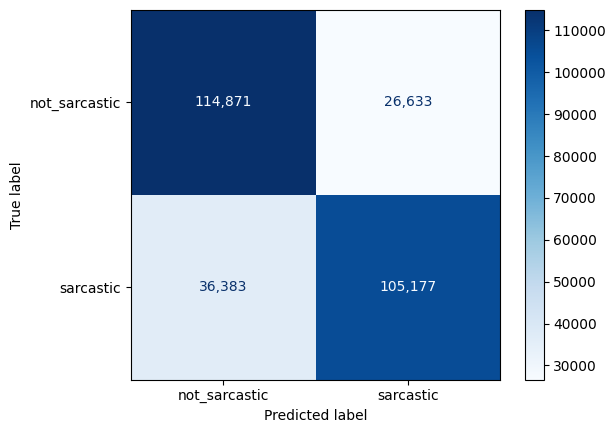

In [33]:
# print classification report
print(classification_report(y_true, y_pred, target_names=['not_sarcastic', 'sarcastic'], digits=4))

# plot confusion matrix
cm = confusion_matrix(y_true, y_pred)   
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['not_sarcastic', 'sarcastic'])
disp.plot(cmap='Blues', values_format=',d')

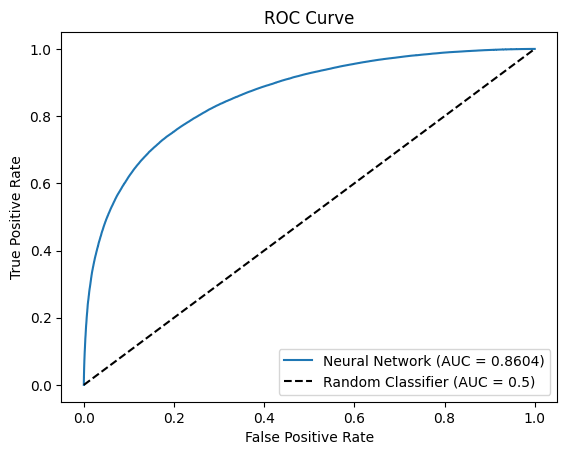

In [34]:
# compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc_test = roc_auc_score(y_true, y_prob)

# plot ROC curve

plt.figure()
plt.plot(fpr, tpr, label=f'Neural Network (AUC = {auc_test:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()